In [1]:
import qiskit
print(qiskit.__version__)

2.5.2


<IPython.core.display.Latex object>

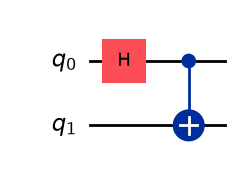

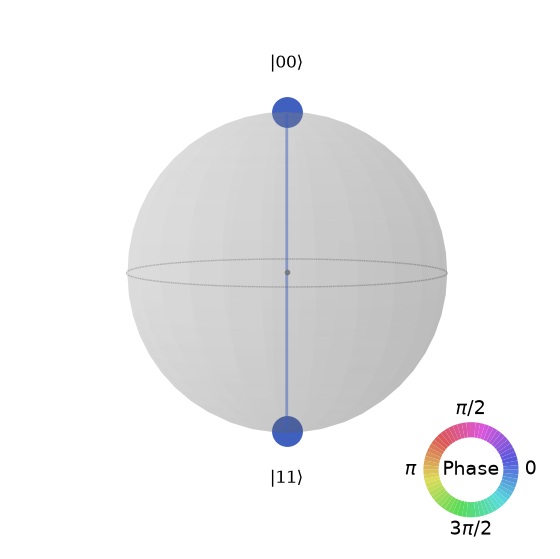

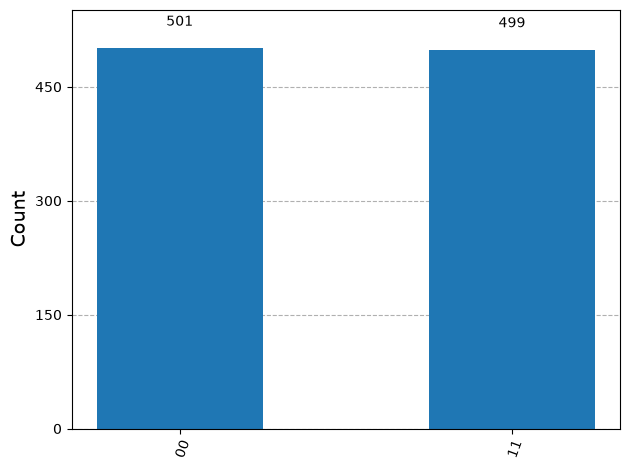

In [8]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_state_qsphere
import sympy
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler

def execute_circuit_sv(quantum_circuit):
    statevector_results = Statevector(quantum_circuit)
    circuit_diagram = quantum_circuit.draw("mpl")
    q_sphere = plot_state_qsphere(statevector_results)
    return statevector_results, circuit_diagram, q_sphere

def run_circuit_and_get_counts(circuit, backend, shots=1000):
    #runs a quantum circuit on a specified beckedn and reutnres the measurement
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(circuit)

    sampler = Sampler(mode=backend)
    job = sampler.run([isa_circuit], shots=shots)
    result = job.result()

    return result[0].data.meas.get_counts()

# 사용 예
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

sv, diagram, qsphere = execute_circuit_sv(qc)
qc.measure_all()
display(sv.draw("latex"))
display(diagram)
display(qsphere)
backend = AerSimulator()
counts = run_circuit_and_get_counts(qc, backend, shots=1000)
plot_histogram(counts)

In [21]:
testx = QuantumCircuit(1)
testx.ry(2,0)
display(Statevector(testx).draw("latex"))
testx.x(0)
display(Statevector(testx).draw("latex"))


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [ ]:
testh = QuantumCircuit(1)
testh.h(0)
display(Statevector(testh).draw("latex"))

<IPython.core.display.Latex object>

In [ ]:
testcx = QuantumCircuit(2)
testcx.cx(0,1)
display(Statevector(testcx).draw("latex"))


<IPython.core.display.Latex object>

In [26]:
testcx1 = QuantumCircuit(2)
testcx1.h(0)
testcx1.cx(0,1)
display(Statevector(testcx1).draw("latex"))

<IPython.core.display.Latex object>